# 03 — UCI final model, locked test evaluation and SHAP

This notebook mirrors Mendeley notebook 04 (`04_repeated_nested_cv.ipynb`):

1. Re-tune the model selected in notebook 02 on the **full training
   portion**, using group-aware 5-fold CV, `RandomizedSearchCV(n_iter=10)`
   and high-risk recall scoring. The search refits on all training records.
2. Save the fitted model and its config.
3. Evaluate it **once** on the locked 20% test set.
4. Explain it with SHAP: global importance, a high-risk beeswarm, one
   individual waterfall, and fold stability (Spearman rank correlations).
5. Export metrics, figures and reproducibility metadata.
6. Build the comparison table against the Mendeley results.

Outputs go to `ml_model/uci/models/` and `ml_model/uci/reports/final_model/`.
SHAP values describe the model's outputs. They are not causal or clinical effects.

In [1]:
import sys
from pathlib import Path

# Make ml_model/uci importable whether the notebook runs from
# ml_model/uci/notebooks (default) or from ml_model/uci.
UCI_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "uci_common.py").exists())
sys.path.insert(0, str(UCI_DIR))

import uci_common as uc

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("UCI folder:", UCI_DIR)

import json
import time
from datetime import datetime, timezone
from itertools import combinations

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, shap, sklearn, xgboost
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder

uc.set_plot_style()
versions = {
    "python": sys.version.split()[0],
    "scikit_learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "shap": shap.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
}
print(versions)

reports_dir = uc.REPORTS_DIR
output_dir = reports_dir / "final_model"
output_dir.mkdir(parents=True, exist_ok=True)
uc.MODELS_DIR.mkdir(parents=True, exist_ok=True)

Python: 3.12.10
Interpreter: C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci\.venv\Scripts\python.exe
UCI folder: C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci


C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.12.10', 'scikit_learn': '1.9.1', 'xgboost': '3.4.1', 'shap': '0.52.0', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1'}


## 1. Load data, locked split and the model selected in notebook 02

In [2]:
data = uc.load_train_test()
df = data["df"]
X_train, y_train, groups_train = data["X_train"], data["y_train"], data["groups_train"]
X_test, y_test = data["X_test"], data["y_test"]

saved = pd.read_csv(reports_dir / "locked_split_assignment.csv")
assert (saved.loc[saved["split"] == "test", "row_index"].to_numpy()
        == np.sort(data["test_idx"])).all()
assert not set(groups_train) & set(data["groups_test"])

with open(reports_dir / "model_selection.json", encoding="utf-8") as f:
    selection = json.load(f)

selected_model = selection["selected_model"]
model_slug = selected_model.lower().replace(" ", "_")

print("Selected model:", selected_model)
print("Rule:", selection["rule"])
print("Training records:", len(X_train), "| locked test records:", len(X_test))

Selected model: Random Forest
Rule: Highest mean high-risk recall over the repeated nested CV outer folds (same rule as the Mendeley pipeline); ties at 4 decimals broken by mean macro F1.
Training records: 585 | locked test records: 147


## 2. Final hyperparameter tuning on the full training portion

This is the same procedure as Mendeley notebook 04, step 02: 5-fold
`StratifiedGroupKFold(random_state=42)`, `RandomizedSearchCV(n_iter=10,
random_state=42)` scored on high-risk recall, with `refit=True`. The test
set is not involved.

In [3]:
final_cv = StratifiedGroupKFold(n_splits=uc.FINAL_CV_SPLITS, shuffle=True,
                                random_state=uc.RANDOM_STATE)

final_search = RandomizedSearchCV(
    estimator=uc.build_models()[selected_model],
    param_distributions=uc.PARAMETER_SPACES[selected_model],
    n_iter=uc.N_ITER,
    scoring=uc.HIGH_RISK_RECALL_SCORER,
    cv=final_cv,
    random_state=uc.RANDOM_STATE,
    n_jobs=1,
    refit=True,
    error_score="raise",
)

start = time.time()
final_search.fit(X_train, y_train, groups=groups_train)
final_model = final_search.best_estimator_

print(f"Tuning time: {time.time() - start:.1f} s")
print("Best hyperparameters:")
for k, v in final_search.best_params_.items():
    print(f"  {k}: {v}")
print("Best 5-fold CV high-risk recall:", round(final_search.best_score_, 4))
print("Test records used for tuning: 0")

Tuning time: 19.6 s
Best hyperparameters:
  model__n_estimators: 100
  model__min_samples_leaf: 1
  model__max_depth: None
  model__class_weight: None
Best 5-fold CV high-risk recall: 0.7756
Test records used for tuning: 0


## 3. Save the model

In [4]:
# The LabelEncoder reproduces the fixed mapping exactly, so the bundle has
# the same structure as ml_model/models/aiovy_random_forest.joblib.
label_encoder = LabelEncoder().fit(uc.CLASS_NAMES)
assert dict(zip(label_encoder.classes_,
                label_encoder.transform(label_encoder.classes_))) == uc.LABEL_MAPPING

model_path = uc.MODELS_DIR / f"aiovy_uci_{model_slug}.joblib"
config_path = uc.MODELS_DIR / f"aiovy_uci_{model_slug}_config.json"

joblib.dump({
    "model": final_model,
    "label_encoder": label_encoder,
    "label_mapping": uc.LABEL_MAPPING,
    "features": uc.FEATURES,
    "feature_units": uc.FEATURE_UNITS,
}, model_path)

bundle = joblib.load(model_path)
assert bundle["features"] == uc.FEATURES
assert list(bundle["label_encoder"].classes_) == uc.CLASS_NAMES
assert (bundle["model"].predict(X_train) == final_model.predict(X_train)).all()

print("Saved:", model_path, f"({model_path.stat().st_size / 1024:.0f} KB)")

Saved: C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci\models\aiovy_uci_random_forest.joblib (2212 KB)


## 4. Locked test evaluation (run once)

The model and hyperparameters are fixed. The saved bundle is reloaded
from disk and predicts the 147 locked test records.

In [5]:
model = bundle["model"]
y_pred = model.predict(X_test[bundle["features"]])
test_probabilities = model.predict_proba(X_test[bundle["features"]])

test_metrics = uc.compute_metrics(y_test, y_pred)

print("=== UCI HELD-OUT TEST RESULTS ===")
print("Model:", selected_model, "| test records:", len(X_test))
for k, v in test_metrics.items():
    print(f"{k}: {v:.4f}")

clinical_codes = [uc.LABEL_MAPPING[c] for c in uc.CLINICAL_ORDER]
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, labels=clinical_codes,
                            target_names=uc.CLINICAL_ORDER, digits=4, zero_division=0))

report_df = pd.DataFrame(classification_report(
    y_test, y_pred, labels=clinical_codes, target_names=uc.CLINICAL_ORDER,
    output_dict=True, zero_division=0)).T
report_df.to_csv(output_dir / "heldout_classification_report.csv", index_label="Class")

=== UCI HELD-OUT TEST RESULTS ===
Model: Random Forest | test records: 147
Accuracy: 0.6939
Macro Precision: 0.6825
Macro Recall: 0.6694
Macro F1: 0.6408
High-Risk Recall: 0.8974

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    low risk     0.6517    0.9062    0.7582        64
    mid risk     0.5625    0.2045    0.3000        44
   high risk     0.8333    0.8974    0.8642        39

    accuracy                         0.6939       147
   macro avg     0.6825    0.6694    0.6408       147
weighted avg     0.6732    0.6939    0.6492       147



Predicted Risk,low risk,mid risk,high risk
Actual Risk,,,
low risk,58,5,1
mid risk,29,9,6
high risk,2,2,35


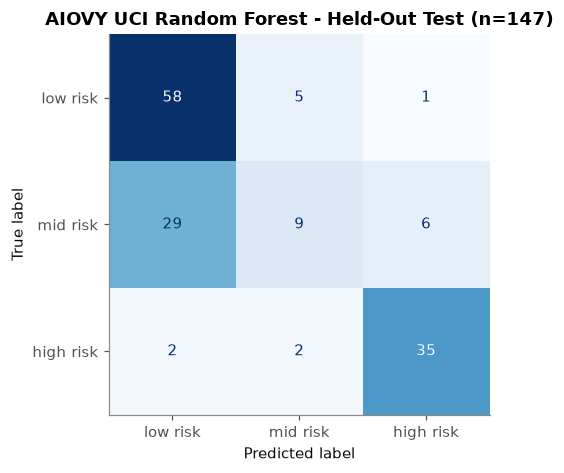

In [6]:
cm = confusion_matrix(y_test, y_pred, labels=clinical_codes)
confusion_df = pd.DataFrame(cm, index=uc.CLINICAL_ORDER, columns=uc.CLINICAL_ORDER)
confusion_df.index.name = "Actual Risk"
confusion_df.columns.name = "Predicted Risk"
confusion_df.to_csv(output_dir / "confusion_matrix.csv")
display(confusion_df)

fig, ax = plt.subplots(figsize=(5.2, 4.4))
ConfusionMatrixDisplay(cm, display_labels=uc.CLINICAL_ORDER).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.grid(False)
ax.set_title(f"AIOVY UCI {selected_model} - Held-Out Test (n={len(X_test)})")
fig.tight_layout()
fig.savefig(output_dir / "confusion_matrix.png", bbox_inches="tight")
plt.show()

In [7]:
actual_high = y_test == uc.HIGH_RISK_CODE
correct_high = int((actual_high & (y_pred == uc.HIGH_RISK_CODE)).sum())
missed_high = int((actual_high & (y_pred != uc.HIGH_RISK_CODE)).sum())
total_high = int(actual_high.sum())

print("=== HIGH-RISK DETECTION ANALYSIS ===")
print("Actual high-risk records:", total_high)
print("Correctly detected:", correct_high)
print("Missed:", missed_high)
print("Missed high-risk predicted as:")
print(pd.Series(label_encoder.inverse_transform(
    y_pred[actual_high & (y_pred != uc.HIGH_RISK_CODE)])).value_counts())

assert np.isclose(correct_high / total_high, test_metrics["High-Risk Recall"])

pd.DataFrame([{
    "Model": selected_model, "Test Records": len(X_test), **test_metrics,
    "Actual High Risk": total_high,
    "Correctly Detected High Risk": correct_high,
    "Missed High Risk": missed_high,
}]).to_csv(output_dir / "heldout_test_metrics.csv", index=False)

predictions_df = X_test.copy()
predictions_df.index = data["test_idx"]
predictions_df["actual_risk"] = label_encoder.inverse_transform(y_test)
predictions_df["predicted_risk"] = label_encoder.inverse_transform(y_pred)
for i, name in enumerate(label_encoder.classes_):
    predictions_df[f"prob_{name.replace(' ', '_')}"] = test_probabilities[:, i]
predictions_df.sort_index().to_csv(output_dir / "heldout_test_predictions.csv",
                                   index_label="source_row_index")
print("\nPASS: held-out results exported")

=== HIGH-RISK DETECTION ANALYSIS ===
Actual high-risk records: 39
Correctly detected: 35
Missed: 4
Missed high-risk predicted as:
mid risk    2
low risk    2
Name: count, dtype: int64

PASS: held-out results exported


In [8]:
# Config in the same format as ml_model/models/aiovy_random_forest_config.json,
# extended with the label mapping, metrics and library versions.
nested_means = selection["nested_cv_means"][selected_model]
nested_stds = selection["nested_cv_stds"][selected_model]

config = {
    "model": selected_model,
    "dataset": uc.DATASET_NAME,
    "dataset_records": len(df),
    "training_records": len(X_train),
    "locked_test_records": len(X_test),
    "features": uc.FEATURES,
    "feature_units": uc.FEATURE_UNITS,
    "labels": label_encoder.classes_.tolist(),
    "label_mapping": uc.LABEL_MAPPING,
    "high_risk_class_code": int(uc.HIGH_RISK_CODE),
    "best_params": final_search.best_params_,
    "cv_high_risk_recall": float(final_search.best_score_),
    "cv_folds": uc.FINAL_CV_SPLITS,
    "search_iterations": uc.N_ITER,
    "smote_used": False,
    "random_state": uc.RANDOM_STATE,
    "grouping": "one group per distinct six-feature vector (pd.util.hash_pandas_object)",
    "split": {
        "method": "StratifiedGroupKFold(n_splits=5, shuffle=True), first fold = locked test",
        "test_size": uc.TEST_SIZE,
        "random_state": uc.RANDOM_STATE,
        "group_overlap": 0,
    },
    "selection_rule": selection["rule"],
    "repeated_nested_cv": {
        "repeats": len(uc.REPEAT_SEEDS),
        "outer_folds": uc.OUTER_SPLITS,
        "inner_folds": uc.INNER_SPLITS,
        "mean": nested_means,
        "std": nested_stds,
    },
    "test_metrics": {k.lower().replace(" ", "_").replace("-", "_"): float(v)
                     for k, v in test_metrics.items()},
    "versions": versions,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
}

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)
print("Saved:", config_path)
print(json.dumps(config["test_metrics"], indent=2))

Saved: C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci\models\aiovy_uci_random_forest_config.json
{
  "accuracy": 0.6938775510204082,
  "macro_precision": 0.6825062421972534,
  "macro_recall": 0.6694104506604507,
  "macro_f1": 0.6407891551682401,
  "high_risk_recall": 0.8974358974358975
}


## 5. SHAP explainability

The setup mirrors Mendeley notebook 04: up to 200 locked-test records
(`random_state=42`). With only 147 test records, all of them are used.
Global importance is the mean absolute SHAP value over records and all
three classes. The beeswarm and waterfall explain the **high-risk**
output.

`TreeExplainer` is used for Random Forest and XGBoost, and
`LinearExplainer` for Logistic Regression. The output space depends on the
model: probability for Random Forest, log-odds for XGBoost and Logistic
Regression.

In [9]:
X_shap = X_test.sample(n=min(uc.SHAP_SAMPLE_SIZE, len(X_test)),
                       random_state=uc.RANDOM_STATE)

explainer = uc.make_shap_explainer(selected_model, model, X_train)
start = time.time()
shap_values = uc.shap_explain(selected_model, model, explainer, X_shap)
output_space = uc.shap_output_space(selected_model)

print("Explainer:", type(explainer).__name__)
print("SHAP output space:", output_space)
print("SHAP sample size:", len(X_shap))
print("SHAP values shape:", shap_values.values.shape)
print(f"Time: {time.time() - start:.2f} s")

assert shap_values.values.shape == (len(X_shap), len(uc.FEATURES), len(uc.CLASS_NAMES))

# Additivity: base value + sum of contributions = model output, for every record
reconstructed = shap_values.base_values + shap_values.values.sum(axis=1)
max_error = np.abs(reconstructed - uc.model_output(selected_model, model, X_shap)).max()
print("Max additivity error:", max_error)
assert max_error < 1e-4

Explainer: TreeExplainer
SHAP output space: predicted probability
SHAP sample size: 147
SHAP values shape: (147, 6, 3)
Time: 0.52 s
Max additivity error: 2.4936649967166602e-15


,Feature,Mean Absolute SHAP
3,BS,0.131172
1,SystolicBP,0.077497
4,BodyTemp,0.058539
0,Age,0.050776
5,HeartRate,0.029363
2,DiastolicBP,0.028922


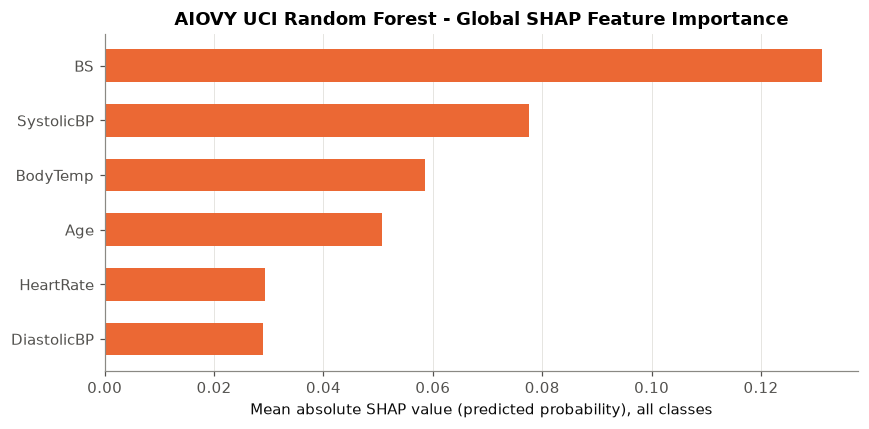

In [10]:
importance_df = pd.DataFrame({
    "Feature": uc.FEATURES,
    "Mean Absolute SHAP": np.abs(shap_values.values).mean(axis=(0, 2)),
}).sort_values("Mean Absolute SHAP", ascending=False)
display(importance_df)
importance_df.to_csv(output_dir / "shap_global_importance.csv", index=False)

ordered = importance_df.sort_values("Mean Absolute SHAP")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ordered["Feature"], ordered["Mean Absolute SHAP"],
        color=uc.MODEL_COLORS[selected_model], height=0.6)
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Mean absolute SHAP value ({output_space}), all classes")
ax.set_title(f"AIOVY UCI {selected_model} - Global SHAP Feature Importance")
fig.tight_layout()
fig.savefig(output_dir / "shap_global_importance.png", bbox_inches="tight")
plt.show()

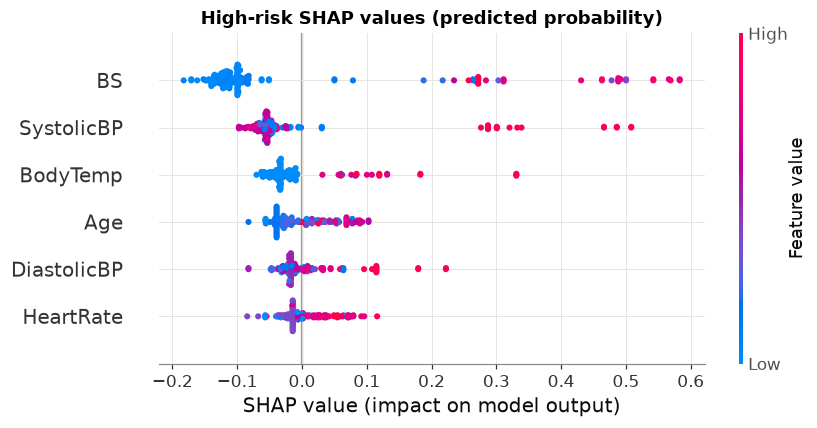

In [11]:
high_idx = int(uc.HIGH_RISK_CODE)
high_risk_shap = shap_values[:, :, high_idx]

shap.plots.beeswarm(high_risk_shap, max_display=6, show=False)
plt.title(f"High-risk SHAP values ({output_space})")
plt.savefig(output_dir / "shap_high_risk_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

=== EXAMPLE RECORD (locked test row 19 ) ===


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
19,50,140,90,15.0,98.0,90


Actual risk: high risk
Predicted risk: high risk
  high risk: 98.13%
  low risk: 0.00%
  mid risk: 1.87%


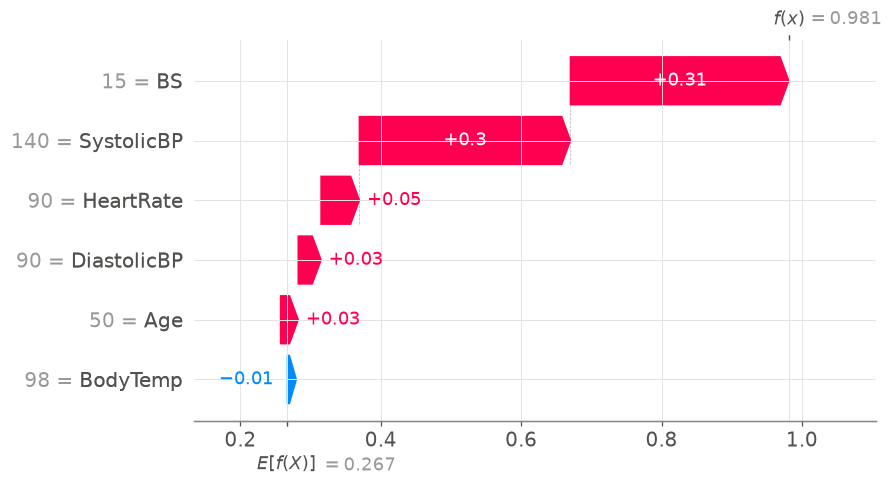


SHAP reconstruction (predicted probability): 0.981333
Model output: 0.981333
PASS: individual SHAP explanation verified


In [12]:
# Individual explanation: first record in the SHAP sample predicted as high risk
sample_predictions = model.predict(X_shap)
high_positions = np.where(sample_predictions == uc.HIGH_RISK_CODE)[0]
assert len(high_positions) > 0, "No predicted high-risk records in SHAP sample"

patient_position = int(high_positions[0])
patient = X_shap.iloc[[patient_position]]
patient_probabilities = model.predict_proba(patient)[0]

print("=== EXAMPLE RECORD (locked test row", X_shap.index[patient_position], ") ===")
display(patient)
print("Actual risk:", label_encoder.inverse_transform([y_test[X_shap.index[patient_position]]])[0])
print("Predicted risk:", label_encoder.inverse_transform(model.predict(patient))[0])
for label, p in zip(label_encoder.classes_, patient_probabilities):
    print(f"  {label}: {p:.2%}")

shap.plots.waterfall(high_risk_shap[patient_position], max_display=6, show=False)
plt.savefig(output_dir / "shap_individual_waterfall.png", dpi=300, bbox_inches="tight")
plt.show()

reconstructed = float(high_risk_shap.base_values[patient_position]
                      + high_risk_shap.values[patient_position].sum())
actual = float(uc.model_output(selected_model, model, patient)[0, high_idx])
print(f"\nSHAP reconstruction ({output_space}):", round(reconstructed, 6))
print("Model output:", round(actual, 6))
assert np.isclose(reconstructed, actual, atol=1e-4)
print("PASS: individual SHAP explanation verified")

## 6. SHAP stability across group-aware folds

This follows Mendeley notebook 04, step 05. The selected configuration
is refitted on each of 5 group-aware training folds
(`StratifiedGroupKFold(random_state=42)`). Each fold model is explained
on the **same fixed reference sample** of up to 200 training records,
and the high-risk mean |SHAP| per feature is compared across folds with
pairwise Spearman rank correlations (10 pairs). The locked test set is
excluded from this analysis.

In [13]:
X_reference = X_train.sample(n=min(uc.SHAP_SAMPLE_SIZE, len(X_train)),
                             random_state=uc.RANDOM_STATE)
stability_cv = StratifiedGroupKFold(n_splits=uc.STABILITY_FOLDS, shuffle=True,
                                    random_state=uc.RANDOM_STATE)

fold_importances = []
for fold, (tr, val) in enumerate(stability_cv.split(X_train, y_train, groups_train), 1):
    assert not set(groups_train[tr]) & set(groups_train[val])
    fold_model = clone(final_model).fit(X_train.iloc[tr], y_train[tr])
    fold_explainer = uc.make_shap_explainer(selected_model, fold_model, X_train.iloc[tr])
    fold_shap = uc.shap_explain(selected_model, fold_model, fold_explainer, X_reference)
    fold_importances.append(np.abs(fold_shap.values[:, :, high_idx]).mean(axis=0))
    print(f"Fold {fold}/{uc.STABILITY_FOLDS} completed")

stability_df = pd.DataFrame(fold_importances, columns=uc.FEATURES,
                            index=[f"Fold {i}" for i in range(1, uc.STABILITY_FOLDS + 1)])
display(stability_df.round(4))
assert stability_df.shape == (5, 6) and np.isfinite(stability_df.to_numpy()).all()

correlation_df = pd.DataFrame([
    {"Fold A": a, "Fold B": b,
     "Spearman rho": spearmanr(stability_df.loc[a], stability_df.loc[b]).statistic}
    for a, b in combinations(stability_df.index, 2)
])
display(correlation_df.round(4))
assert len(correlation_df) == 10 and correlation_df["Spearman rho"].notna().all()

mean_rho = correlation_df["Spearman rho"].mean()
min_rho = correlation_df["Spearman rho"].min()
max_rho = correlation_df["Spearman rho"].max()
print(f"Mean Spearman rho: {mean_rho:.4f} | min: {min_rho:.4f} | max: {max_rho:.4f}")

rank_df = stability_df.rank(axis=1, ascending=False, method="average")
stability_summary = pd.DataFrame({
    "Feature": uc.FEATURES,
    "Mean SHAP": stability_df.mean().values,
    "SHAP Std": stability_df.std().values,
    "Mean Rank": rank_df.mean().values,
    "Rank Std": rank_df.std().values,
}).sort_values("Mean Rank")
display(stability_summary.round(4))

stability_df.to_csv(output_dir / "shap_fold_importance.csv", index_label="Fold")
correlation_df.to_csv(output_dir / "shap_rank_correlations.csv", index=False)
stability_summary.to_csv(output_dir / "shap_stability_summary.csv", index=False)

Fold 1/5 completed


Fold 2/5 completed


Fold 3/5 completed


Fold 4/5 completed


Fold 5/5 completed


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
Fold 1,0.0384,0.0880,0.0442,0.1680,0.0506,0.0298
Fold 2,0.0402,0.1099,0.0386,0.1637,0.0499,0.0243
Fold 3,0.0349,0.0876,0.0470,0.1856,0.0461,0.0335
Fold 4,0.0409,0.0960,0.0363,0.1668,0.0392,0.0370
Fold 5,0.0423,0.0827,0.0389,0.1749,0.0498,0.0293


,Fold A,Fold B,Spearman rho
0,Fold 1,Fold 2,0.9429
1,Fold 1,Fold 3,0.9429
2,Fold 1,Fold 4,0.7143
3,Fold 1,Fold 5,0.9429
4,Fold 2,Fold 3,0.8286
5,Fold 2,Fold 4,0.8857
6,Fold 2,Fold 5,1.0000
7,Fold 3,Fold 4,0.6000
8,Fold 3,Fold 5,0.8286
9,Fold 4,Fold 5,0.8857


Mean Spearman rho: 0.8571 | min: 0.6000 | max: 1.0000


,Feature,Mean SHAP,SHAP Std,Mean Rank,Rank Std
3,BS,0.1718,0.0087,1.0,0.0000
1,SystolicBP,0.0928,0.0107,2.0,0.0000
4,BodyTemp,0.0471,0.0048,3.4,0.5477
0,Age,0.0393,0.0029,4.2,0.8367
2,DiastolicBP,0.0410,0.0044,4.6,1.1402
5,HeartRate,0.0308,0.0048,5.8,0.4472


## 7. Export metadata and verify outputs

In [14]:
metadata = {
    "project": "AIOVY",
    "notebook": "03_uci_nested_cv_and_shap.ipynb",
    "experiment": f"UCI final {selected_model} evaluation and SHAP analysis",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": uc.DATASET_NAME,
    "dataset_records": len(df),
    "training_records": len(X_train),
    "test_records": len(X_test),
    "features": uc.FEATURES,
    "classes": label_encoder.classes_.tolist(),
    "label_mapping": uc.LABEL_MAPPING,
    "model": selected_model,
    "selected_hyperparameters": final_search.best_params_,
    "smote_used": False,
    "split": config["split"],
    "test_metrics": config["test_metrics"],
    "shap": {
        "explainer": type(explainer).__name__,
        "output_space": output_space,
        "sample_size": len(X_shap),
        "stability_folds": uc.STABILITY_FOLDS,
        "stability_reference_size": len(X_reference),
        "mean_pairwise_spearman": float(mean_rho),
        "min_pairwise_spearman": float(min_rho),
        "max_pairwise_spearman": float(max_rho),
    },
    "versions": versions,
    "limitations": [
        "Clinical validity not established",
        "Small dataset (732 records, 415 distinct feature vectors)",
        "Duplicate rows kept on purpose; handled with group-aware splits",
        "35 feature vectors carry conflicting labels (accuracy ceiling 93.0%)",
        "Risk-label provenance of the UCI dataset is not documented",
        "SHAP stability uses a fixed training reference sample",
    ],
}
with open(output_dir / "experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

required = [
    "heldout_test_metrics.csv", "heldout_classification_report.csv",
    "confusion_matrix.csv", "confusion_matrix.png", "heldout_test_predictions.csv",
    "shap_global_importance.csv", "shap_global_importance.png",
    "shap_high_risk_beeswarm.png", "shap_individual_waterfall.png",
    "shap_fold_importance.csv", "shap_rank_correlations.csv",
    "shap_stability_summary.csv", "experiment_metadata.json",
]
for name in required:
    path = output_dir / name
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty: {name}"
    print("PASS:", name)
for path in (model_path, config_path):
    assert path.exists() and path.stat().st_size > 0
    print("PASS:", path.name)

assert int(confusion_df.to_numpy().sum()) == len(X_test)
print("\nALL EXPORT CHECKS PASSED")

PASS: heldout_test_metrics.csv
PASS: heldout_classification_report.csv
PASS: confusion_matrix.csv
PASS: confusion_matrix.png
PASS: heldout_test_predictions.csv
PASS: shap_global_importance.csv
PASS: shap_global_importance.png
PASS: shap_high_risk_beeswarm.png
PASS: shap_individual_waterfall.png
PASS: shap_fold_importance.csv
PASS: shap_rank_correlations.csv
PASS: shap_stability_summary.csv
PASS: experiment_metadata.json
PASS: aiovy_uci_random_forest.joblib
PASS: aiovy_uci_random_forest_config.json

ALL EXPORT CHECKS PASSED


## 8. Comparison table against the Mendeley results

The Mendeley values are read (read-only) from
`ml_model/reports/repeated_nested_cv_summary.csv` and
`ml_model/reports/notebook_04/heldout_test_metrics.csv`. The Mendeley
summary has no macro precision or macro recall, so those cells are
empty. The narrative comparison is in
`reports/uci_vs_mendeley_comparison.md`.

In [15]:
mendeley_cv = pd.read_csv(uc.MENDELEY_REPORTS_DIR / "repeated_nested_cv_summary.csv",
                          header=[0, 1], index_col=0)
mendeley_test = pd.read_csv(uc.MENDELEY_REPORTS_DIR / "notebook_04" / "heldout_test_metrics.csv")
uci_cv = pd.read_csv(reports_dir / "repeated_nested_cv_summary.csv",
                     header=[0, 1], index_col=0)

def fmt(table, model, metric):
    if metric not in table.columns.get_level_values(0) or model not in table.index:
        return ""
    return f"{table.loc[model, (metric, 'mean')]:.4f} ± {table.loc[model, (metric, 'std')]:.4f}"

rows = []
for model_name in uci_cv.index:
    for metric in uc.METRIC_COLUMNS:
        rows.append({"Model": model_name, "Metric": metric,
                     "UCI nested CV (mean ± std)": fmt(uci_cv, model_name, metric),
                     "Mendeley nested CV (mean ± std)": fmt(mendeley_cv, model_name, metric)})
comparison_cv = pd.DataFrame(rows)
display(comparison_cv)
comparison_cv.to_csv(reports_dir / "uci_vs_mendeley_nested_cv.csv", index=False)

comparison_test = pd.DataFrame({
    "UCI": {"Model": selected_model, "Test Records": len(X_test),
            **{m: round(v, 4) for m, v in test_metrics.items()}},
    "Mendeley": {"Model": mendeley_test.loc[0, "Model"],
                 "Test Records": int(mendeley_test.loc[0, "Test Records"]),
                 **{m: round(float(mendeley_test.loc[0, m]), 4)
                    for m in ["Accuracy", "Macro F1", "High-Risk Recall"]}},
}).reindex(["Model", "Test Records"] + uc.METRIC_COLUMNS)
display(comparison_test)
comparison_test.to_csv(reports_dir / "uci_vs_mendeley_heldout_test.csv", index_label="Metric")

,Model,Metric,UCI nested CV (mean ± std),Mendeley nested CV (mean ± std)
0,Logistic Regression,Accuracy,0.6199 ± 0.0620,0.5885 ± 0.0093
1,Logistic Regression,Macro Precision,0.6180 ± 0.0605,
2,Logistic Regression,Macro Recall,0.6103 ± 0.0665,
3,Logistic Regression,Macro F1,0.6069 ± 0.0652,0.5802 ± 0.0098
4,Logistic Regression,High-Risk Recall,0.7109 ± 0.1202,0.4657 ± 0.0208
5,Random Forest,Accuracy,0.6484 ± 0.0353,0.9219 ± 0.0082
6,Random Forest,Macro Precision,0.6236 ± 0.0586,
7,Random Forest,Macro Recall,0.6316 ± 0.0421,
8,Random Forest,Macro F1,0.6157 ± 0.0498,0.9215 ± 0.0083
9,Random Forest,High-Risk Recall,0.7991 ± 0.0672,0.8670 ± 0.0182


,UCI,Mendeley
Model,Random Forest,Random Forest
Test Records,147,1213
Accuracy,0.6939,0.9291
Macro Precision,0.6825,NaN
Macro Recall,0.6694,NaN
Macro F1,0.6408,0.929
High-Risk Recall,0.8974,0.8653
